<a href="https://colab.research.google.com/github/JFish72/CSC-349-Machine-Learning-/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task One:**
*   Repeating the same process as the last assignment, the wine dataset can me directly imported from Scikit learn. This is a much smoother process compared to searching for and then downloading outside datasets in the form of CSV files.  
*   For this step, I am simply placing the information from the dataset into a pandas DataFrame, returning the datasets dimensions, creating a statistical summary, and checking for missing values.
*   To prepare our data for further tasks and computation, it is best to scale our data to prevent large numerical differences from holding too much weight in our models. To display the difference that the StandardScaler can make to the feature spread, I am using two boxplots.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()

X = pd.DataFrame(wine.data, columns = wine.feature_names)
y = wine.target

print("Dataset Dimensions:", X.shape)
print("Statistical Summary:\n", X.describe().round(2).to_string())
print("Missing Values:\n", X.isnull().sum().to_string())


Dataset Dimensions: (178, 13)
Statistical Summary:
        alcohol  malic_acid     ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity     hue  od280/od315_of_diluted_wines  proline
count   178.00      178.00  178.00             178.00     178.00         178.00      178.00                178.00           178.00           178.00  178.00                        178.00   178.00
mean     13.00        2.34    2.37              19.49      99.74           2.30        2.03                  0.36             1.59             5.06    0.96                          2.61   746.89
std       0.81        1.12    0.27               3.34      14.28           0.63        1.00                  0.12             0.57             2.32    0.23                          0.71   314.91
min      11.03        0.74    1.36              10.60      70.00           0.98        0.34                  0.13             0.41             1.28    0.48             

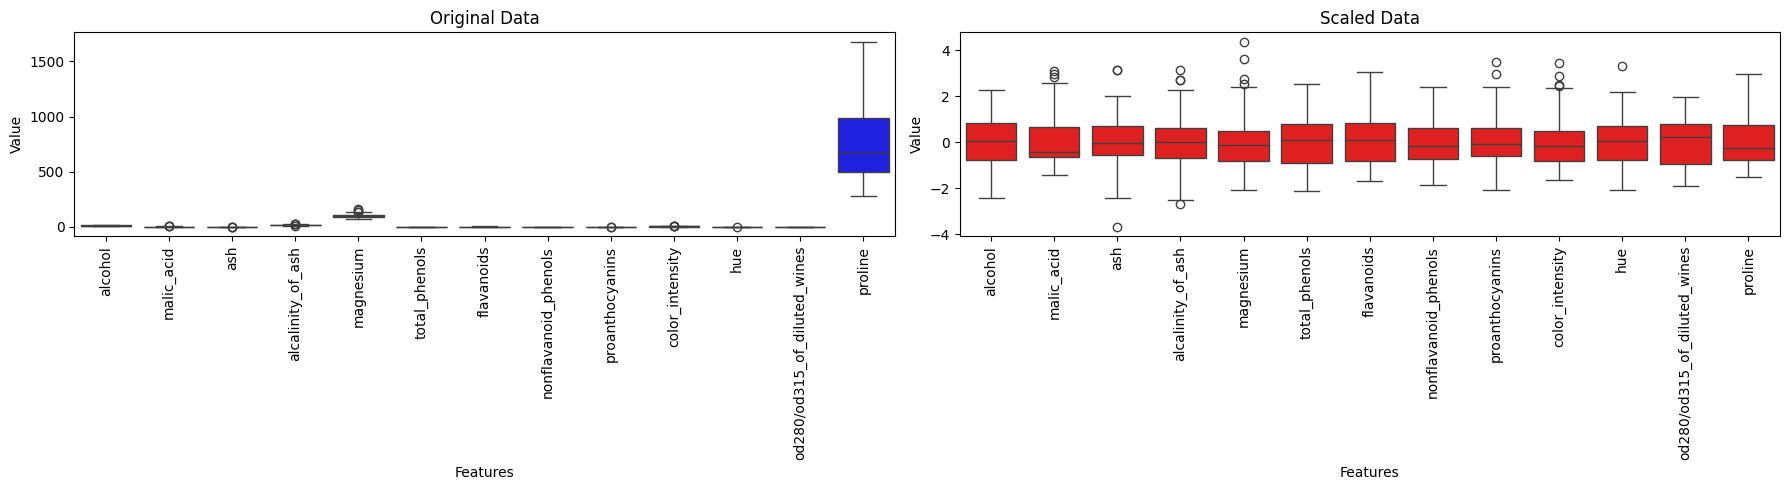

In [31]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns = X.columns)

fig, axes = plt.subplots(1, 2, figsize = (18, 5))

sns.boxplot(data = X, ax = axes[0], color = 'blue')
sns.boxplot(data = X_scaled_df, ax = axes[1], color = 'red')

axes[0].set_title('Original Data')
axes[1].set_title('Scaled Data')

for ax in axes:
    ax.tick_params(axis = 'x', rotation = 90)
    ax.set_xlabel('Features')
    ax.set_ylabel('Value')

plt.tight_layout()
plt.show()



**Task Two:**
*   To illustrate the difference that the hyperparameter k can create, I am iterating from 1 to 10 and displaying the changes in the model. The inertia value measures the squared distance within a cluster and will create my elbow curve. The silhouette score examines the in-cluster cohesion in comparison to the other clusters around it. Since there is a comparison being made, in this task, k = 1 will not have a silhouette score.
*   After all iterations are complete, it is important to see which method suggests which k value. To highlight this choice and the explanation behind it, I will plot the points for a better visual representation.  


Elbow Method Suggested K: 3
Silhouette Method Suggested K: 3


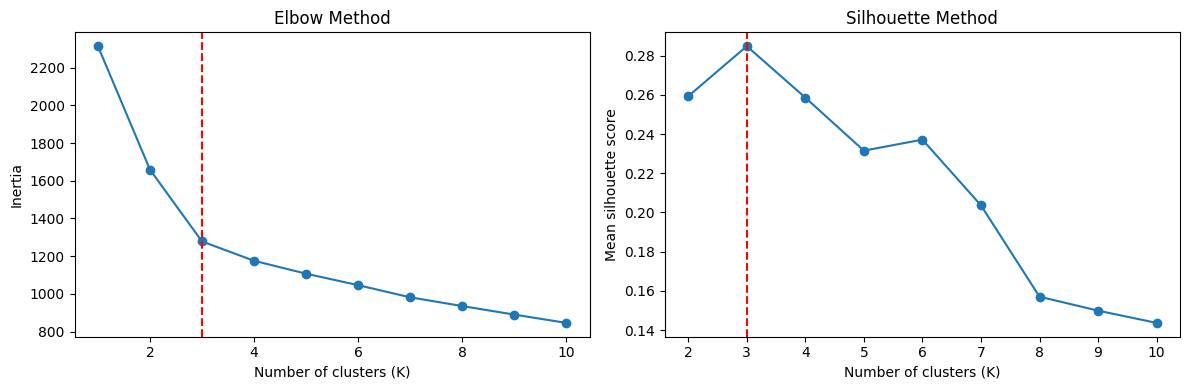

In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 20)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    if k >= 2:
        silhouette_scores.append(silhouette_score(X_scaled, labels))

points = np.column_stack((np.arange(1, 11), inertias)).astype(float)
scaled_points = (points - points.min(axis = 0)) / (points.max(axis = 0) - points.min(axis = 0))

start = scaled_points[0]
end = scaled_points[-1]

direction = end - start

distances = np.abs(direction[0] * (scaled_points[:, 1] - start[1]) - direction[1] * (scaled_points[:, 0] - start[0])) / np.linalg.norm(direction)

ks = np.arange(1, 11)

elbow_k = int((ks)[np.argmax(distances)])
silhouette_k = int(ks[1:][np.argmax(silhouette_scores)])

print("Elbow Method Suggested K:", elbow_k)
print("Silhouette Method Suggested K:", silhouette_k)

fig, axes = plt.subplots(1, 2, figsize = (12,4))
axes[0].plot(ks, inertias, 'o-'); axes[0].axvline(elbow_k, color = 'red', linestyle = '--')
axes[0].set(title = 'Elbow Method', xlabel = 'Number of clusters (K)', ylabel = 'Inertia')
axes[1].plot(ks[1:], silhouette_scores, 'o-'); axes[1].axvline(silhouette_k, color = 'red', linestyle = '--')
axes[1].set(title = 'Silhouette Method', xlabel = 'Number of clusters (K)', ylabel = 'Mean silhouette score')

plt.tight_layout()
plt.show()

**Task Three:**
*   To reduce the 13 original features of the dataset to two principal components, I have to perform PCA. Using a new K-means model with k set to 3, which, from above, is the most efficient number of clusters.
*   The Voronoi diagram partitions the regions closest to each of the centroids. On the diagram, sample points are organized by color with the centroids marked separately.



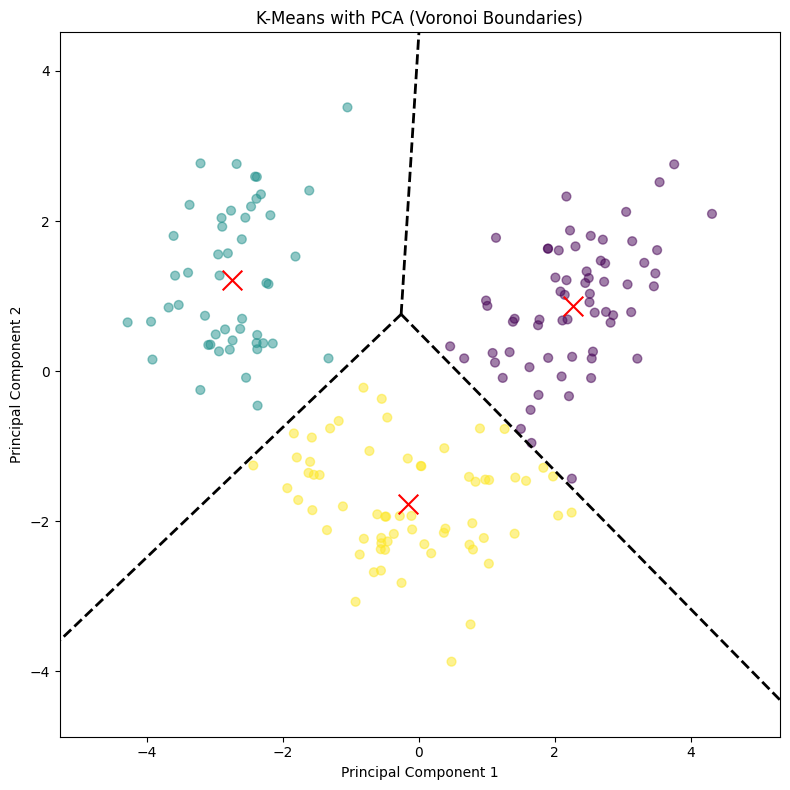

In [33]:
from sklearn.decomposition import PCA
from scipy.spatial import Voronoi, voronoi_plot_2d

X_pca = PCA(n_components = 2).fit_transform(X_scaled)

kmeans_2d = KMeans(n_clusters = 3, random_state = 42, n_init = 20)

labels_2d = kmeans_2d.fit_predict(X_pca)

centers_2d = kmeans_2d.cluster_centers_

vor = Voronoi(centers_2d)

fig, ax = plt.subplots(figsize = (8, 8))
voronoi_plot_2d(vor, ax = ax, show_vertices = False, show_points = False, line_width = 2, line_color = 'black')
ax.scatter(X_pca[:, 0], X_pca[:, 1], c = labels_2d, cmap = 'viridis', s = 40, alpha = 0.5)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c = 'red', s = 200, marker = 'x')
ax.set(xlabel = 'Principal Component 1', ylabel = 'Principal Component 2', title = 'K-Means with PCA (Voronoi Boundaries)')
ax.set_xlim(X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1)
ax.set_ylim(X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1)
plt.tight_layout()
plt.show()



**Task 4:**
*   Moving away from PCA and returning to all 13 features, I am selecting 5 wine samples to compute a distance matrix, one closest to each of the three centroids and 2 more that are similar in distance from the centroids. For each wine sample selected, the Euclidean distance will be calculated from the three centroids. I am continuing to use k = 3 for my k-means as it is the most efficient number of centroids, and it will allow us to follow suit with the above task.
*   My heatmap created will then show the Euclidean distances, with a rectangular outline identifying the minimum distance for each row, determining the samples' hard cluster assignment.



Selected sample indices: [np.int64(106), np.int64(148), np.int64(48), 174, 57]
Hard cluster assignments: [0 1 2 1 2]


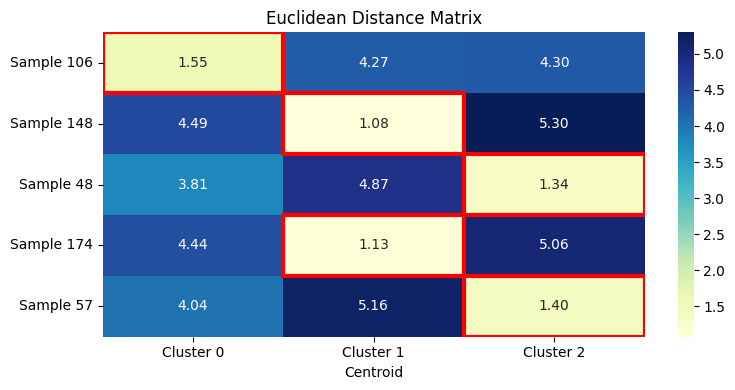

In [34]:
kmeans_13 = KMeans(n_clusters = 3, random_state = 42, n_init = 20)

km_labels = kmeans_13.fit_predict(X_scaled)

all_distances = kmeans_13.transform(X_scaled)

selected = []

for cluster in range(3):
    representative = np.where(km_labels == cluster)[0]
    selected.append(representative[np.argmin(all_distances[representative, cluster])])

ranked = np.argsort(all_distances.min(axis = 1))

selected.extend(int(i) for i in ranked if i not in selected and len(selected) < 5)
selected = selected[:5]

distance_matrix = all_distances[selected]

print("Selected sample indices:", selected)
print("Hard cluster assignments:", km_labels[selected])

fig, ax = plt.subplots(figsize=(8, 4))

sns.heatmap(distance_matrix, annot = True, fmt = '.2f', cmap = 'YlGnBu',
    xticklabels = [f'Cluster {i}' for i in range(3)], yticklabels = [f'Sample {i}' for i in selected], ax = ax)

for row, col in enumerate(np.argmin(distance_matrix, axis = 1)):
    ax.add_patch(plt.Rectangle((col, row), 1, 1, fill = False, edgecolor = 'red', linewidth = 3))

ax.set(title = 'Euclidean Distance Matrix', xlabel = 'Centroid')
plt.tight_layout()
plt.show()

**Task Five:**
*   Using DBSCAN on the 13-dimensional scaled feature space, I can experiment with its two hyperparameters eps and min_samples. As always, when working with new models it is important to understand the effects that hyperparameters can have on the model and how combinations of these hyperparameters work.
*   Hyperparameter eps represents the maximum distance between datapoints for them to be considered neighbors. Min_samples is the minimum number of data points required to be within an eps neighborhood to be declared a core point. In order to understand how they can work together, I am going to experiment on different combinations by comparing their clusters and noise points.
*   From the experiments, I will choose the best configuration of DBSCAN to fit the data before plotting with the previously computed 2D PCA coordinates.  


In [35]:
from sklearn.cluster import DBSCAN

results = []

for eps in [1.5, 2.0, 2.5, 3.0]:
    for min_samples in [3, 5, 8, 11]:
        labels = DBSCAN(eps = eps, min_samples = min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels) - {-1})
        results.append((eps, min_samples, n_clusters, int(np.sum(labels == -1))))

print(pd.DataFrame(results, columns = ['eps', 'min_samples', 'n_clusters', 'noise_points']).to_string(index = False))

 eps  min_samples  n_clusters  noise_points
 1.5            3           8           147
 1.5            5           0           178
 1.5            8           0           178
 1.5           11           0           178
 2.0            3           5            64
 2.0            5           5            85
 2.0            8           3           117
 2.0           11           2           151
 2.5            3           1            23
 2.5            5           1            24
 2.5            8           2            30
 2.5           11           2            35
 3.0            3           2             7
 3.0            5           1            11
 3.0            8           1            11
 3.0           11           1            12


DBSCAN clusters: 5
DBSCAN noise points: 85


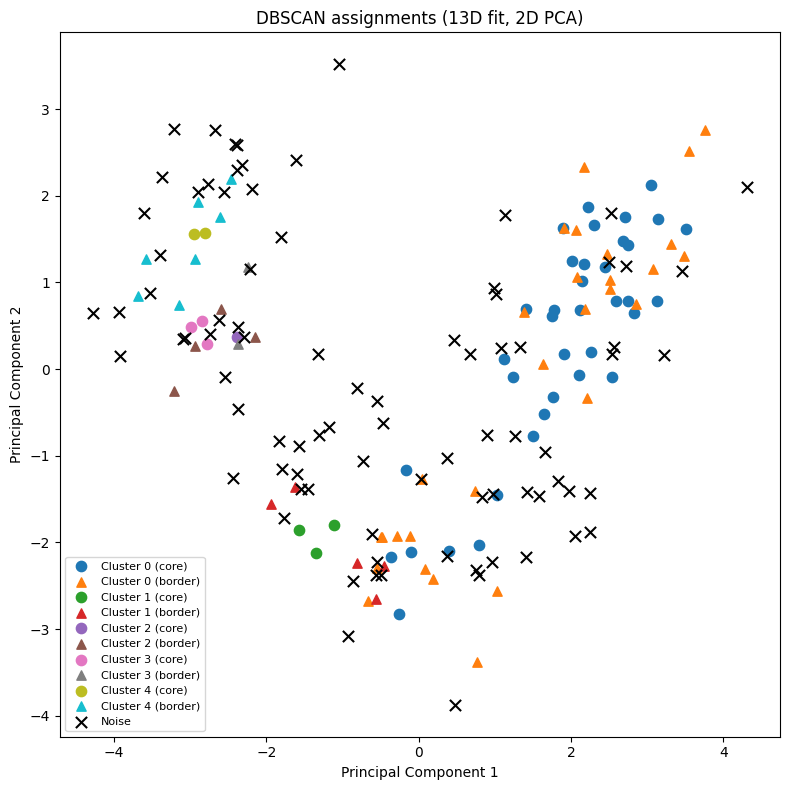

In [36]:
dbscan = DBSCAN(eps = 2, min_samples = 5).fit(X_scaled)

db_labels = dbscan.labels_

print('DBSCAN clusters:', len(set(db_labels) - {-1}))
print('DBSCAN noise points:', int(np.sum(db_labels == -1)))

core_mask = np.zeros(len(X_scaled), dtype = bool)
core_mask[dbscan.core_sample_indices_] = True

fig, ax = plt.subplots(figsize = (8, 8))

for label in sorted(set(db_labels) - {-1}):
    for is_core, marker, size in [(True, 'o', 55), (False, '^', 45)]:
        mask = (db_labels == label) & (core_mask == is_core)
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], marker = marker, s = size,
                   label = f'Cluster {label} ({"core" if is_core else "border"})')

noise = db_labels == -1
ax.scatter(X_pca[noise, 0], X_pca[noise, 1], marker = 'x', s = 65, color = 'black', label = 'Noise')
ax.set(xlabel = 'Principal Component 1', ylabel = 'Principal Component 2', title = 'DBSCAN assignments (13D fit, 2D PCA)')
ax.legend(fontsize = 8, loc = 'best')
plt.tight_layout()
plt.show()



**Task Six:**
*   Pivoting towards a hierarchical density based clustering model, I am using HBSCAN on all 13 of the standardized features. Like DBSCAN, HBSCAN also has important hyperparameters, but for this task we aren't experimenting with these; rather, we are hard-coding them as min_cluster_size = 5 and min_samples = 5. They define the smallest group that can be considered a cluster and control the conservatism of density estimations.  
*   The goal of HBSCAN is to create a hierarchy across different densities and extract what appear to be proper clusters. To highlight the difference between this approach and DBSCAN, I will print out the results for discovered clusters and what is labeled as noise.



HBSCAN clusters: 2
HBSCAN noise points: 58


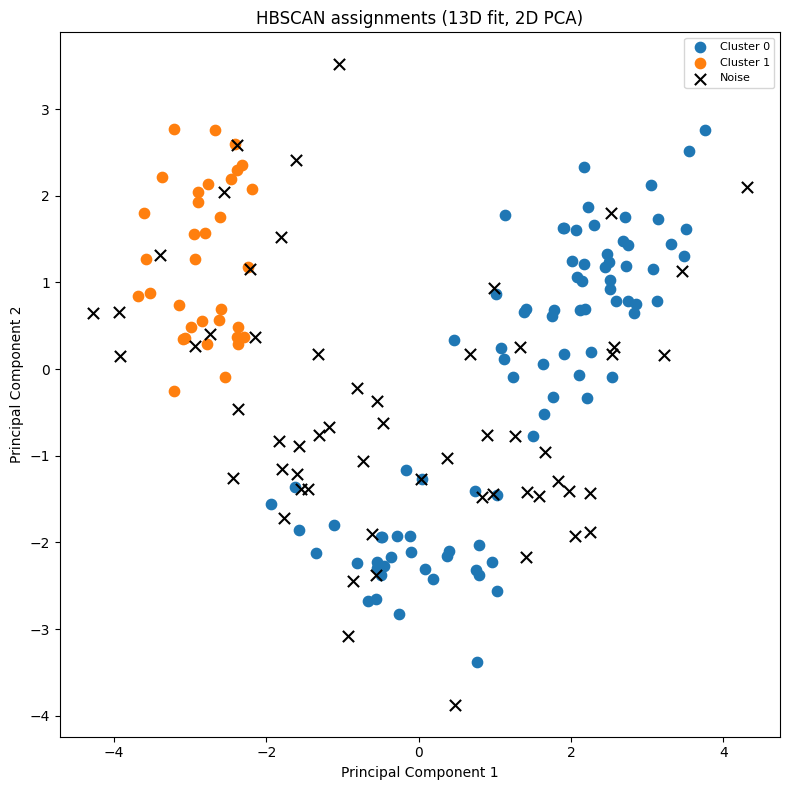

In [37]:
from sklearn.cluster import HDBSCAN

hbdscan = HDBSCAN(min_cluster_size = 5, min_samples = 5)
hbd_labels = hbdscan.fit_predict(X_scaled)

print('HBSCAN clusters:', len(set(hbd_labels) - {-1}))
print('HBSCAN noise points:', int(np.sum(hbd_labels == -1)))

fig, ax = plt.subplots(figsize = (8, 8))

for label in sorted(set(hbd_labels) - {-1}):
    mask = hbd_labels == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], marker = 'o', s = 55, label = f'Cluster {label}')

noise = hbd_labels == -1

ax.scatter(X_pca[noise, 0], X_pca[noise, 1], marker = 'x', s = 65, c = 'black', label = 'Noise')

ax.set(xlabel = 'Principal Component 1', ylabel = 'Principal Component 2', title = 'HBSCAN assignments (13D fit, 2D PCA)')
ax.legend(fontsize = 8, loc = 'best')

plt.tight_layout()
plt.show()

**Task Seven:**
*   To make a single-linkage hierarchical clustering matrix on the scaled features, the two groups with the shortest distance between any pair of their members are merged. To better visualize this process of linking, I am creating a dendrogram that reflects the heirarchical order and distances where samples and clusters merge.
*   HBSCAN uses a single-linkage hierarchy, but uses mutual reachability distances and a condensed hierarchy. The comparison being made from the dendrogram is only a conceptual comparison.



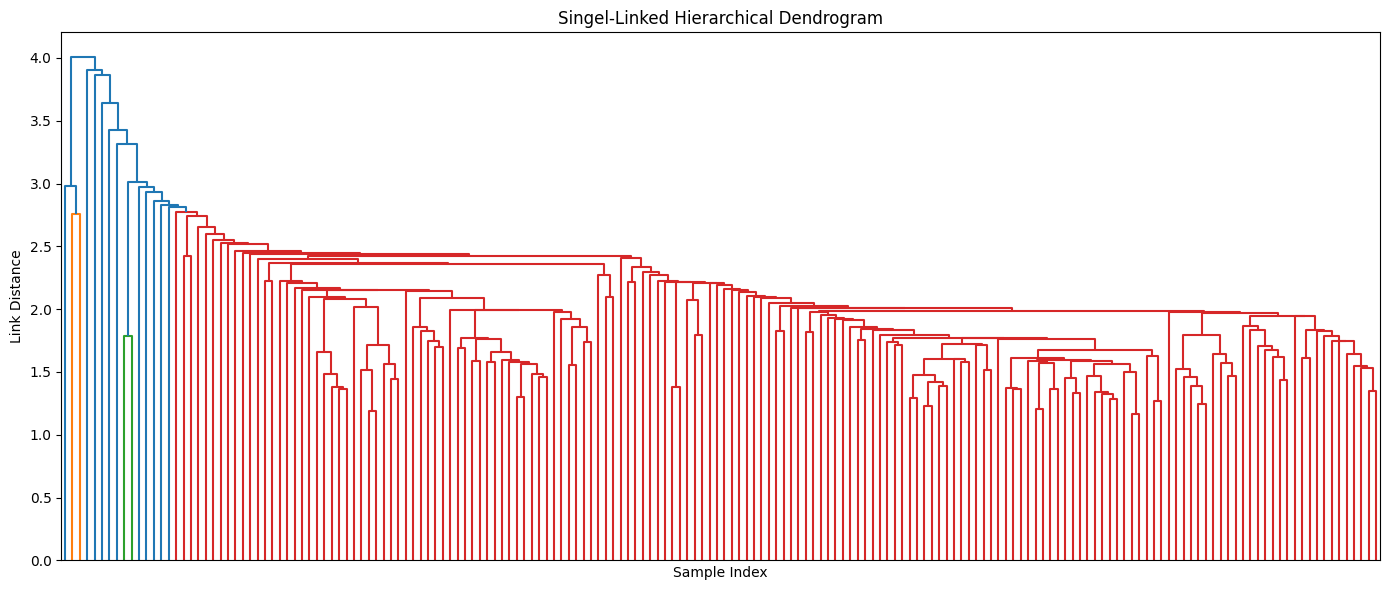

In [38]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method = 'single', metric = 'euclidean')

plt.figure(figsize = (14, 6))
dendrogram(Z, no_labels = True, color_threshold = None)
plt.title('Singel-Linked Hierarchical Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Link Distance')
plt.tight_layout()
plt.show()


**Task Eight:**
*   To begin our test for our final task, an 80/20 train-test split must be done using the ground-truth cluster classes. As a precaution against data leakage, I refit the scaler and the clustering algorithms on the training data. An important focus should be placed on the individual predictions for the algorithms, since K-means can predict test memberships directly, yet DBSCAN and HBSCAN do not have a provided out-of-sample prediction method. To work around this, I am assigning each test sample the cluster label of its closest training sample (nearest-neighbor approximation).   
*   For this task, Cluster IDs and noise are treated as categorical features and are processed by the OneHotEncoder for my Random Forest. One important distincation for my final measurements is that the accuracy score is derived from the test set, while the silhouette scores come from the training set clustering labels.



In [39]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X.to_numpy(), y, stratify = y, test_size = 0.2, random_state = 42)

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = [
    ('K-means', KMeans(n_clusters = 3, random_state = 42, n_init = 20)),
    ('DBSCAN', DBSCAN(eps = 2, min_samples = 5)),
    ('HBSCAN', HDBSCAN(min_cluster_size = 5, min_samples = 5))
]

metrics = []

for name, clusterer in models:

    train_labels = clusterer.fit_predict(X_train_scaled)

    if name == 'K-means':
        test_labels = clusterer.predict(X_test_scaled)
    else:
        nearest = KNeighborsClassifier(n_neighbors = 1)
        nearest.fit(X_train_scaled, train_labels)
        test_labels = nearest.predict(X_test_scaled)

    encoder = OneHotEncoder(handle_unknown = 'ignore', sparse_output = False)

    train_features = encoder.fit_transform(train_labels.reshape(-1, 1))
    test_features = encoder.transform(test_labels.reshape(-1, 1))

    Random_Forest = RandomForestClassifier(n_estimators = 200, random_state = 42)
    Random_Forest.fit(train_features, y_train)

    predictions = Random_Forest.predict(test_features)
    accuracy = accuracy_score(y_test, predictions)

    metrics.append((name, accuracy))
    print(f"{name} Pipeline Accuracy: {accuracy:.4f}")

K-means Pipeline Accuracy: 0.9722
DBSCAN Pipeline Accuracy: 0.8056
HBSCAN Pipeline Accuracy: 0.6389
